# Лабораторный практикум по курсу «Синтез Речи», Университет ИТМО, 2026
**Лабораторная работа №5.** Сервис синтеза

**Цель работы:** Объединение элементов тракта синтеза речи в полноценный сервис Text-to-Speech: на входе текст, на выходе - звук!  
**Выполнила** Иванова Мария Кирилловна  
**Группа** М4121  
**Преподаватели** Рыбин Сергей Витальевич, Чирковский Артем

### 1. Импорты

In [ ]:
import sys
import json
import torch
import librosa

import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter
from IPython.display import Audio, display

lab_dir = Path("../lab5_service")
sys.path.insert(0, str(lab_dir.parent))

from hyperpyyaml import load_hyperpyyaml
from TTS.config.shared_configs import BaseAudioConfig
from TTS.utils.audio import AudioProcessor
from lab5_service.tts_pipeline import SAMPLE_RATE, SIL, TTSPipeline, lookup_key

### 2. Проверка вокодера

In [2]:
for label, filename in [
    ("1. Оригинал", "natural.wav"),
    ("2. Копи-синтез HiFi-GAN", "copysynth_hifigan.wav"),
    ("3. Копи-синтез Griffin–Lim", "copysynth_griffinlim.wav"),
]:
    path = lab_dir / "audio" / filename
    if not path.is_file():
        path = lab_dir / filename

    print(label)
    display(Audio(filename=str(path)))

1. Оригинал


2. Копи-синтез HiFi-GAN


3. Копи-синтез Griffin–Lim


Перенос файлов WAV в audio/

In [4]:
audio_dir = lab_dir / "audio"
audio_dir.mkdir(exist_ok=True)

for filename in ("natural.wav", "copysynth_hifigan.wav", "copysynth_griffinlim.wav"):
    destination = audio_dir / filename
    if not destination.exists():
        (lab_dir / filename).rename(destination)

На записи `000000_RUSLAN.wav` копи-синтез HiFi-GAN звучал чисто и разборчиво; на слух отличий от оригинала не было. Вариант с использованием алгоритма Griffin–Lim тоже разборчивый, но звучит более приглушённо.

### 3. Имплементация тракта синтеза речи

#### Схема

`Текст → нормализация → токены → паузы → фонемы → мел → WAV
`
| Модуль | Функция | Стыковка |
|---|---|---|
| `TextNormalizer` | нормализация текста | вызывается внутри тракта; до и после - приведение к NFC |
| токенизатор | разбиение на токены, паузация | пунктуация после слова сохраняется, её использует предиктор пауз; по признакам пауз вставляются `<SIL>` (длительность в аудио задаёт FastSpeech2) |
| G2P | графемы → фонемы | перед словарём снимаются пунктуация, регистр и знак ударения; `<SIL>` сохраняется; фонемы слов склеиваются в одну последовательность. В g2p.py добавлен относительный импорт .rules при использовании G2P как пакета, чтобы подключить его к TTSPipeline. |
| FastSpeech2 + HiFi-GAN | фонемы → мел → waveform | FastSpeech2 получает фонемы через пробел и предсказывает мел-спектрограмму, её озвучивает HiFi-GAN; веса и словари грузятся при создании `TTSPipeline` |

In [ ]:
pipeline = TTSPipeline(
    run_dir=lab_dir.parent / "lab4_acoustic" / "saved_runs",
    device="cpu",
)

Проверка тракта:
- Слова приводятся к нижнему регистру, знак ударения удаляется, буква `ё` сохраняется.
- Токен `<SIL>` проходит через транскриптор без изменений.

In [3]:
for word, expected in [("ЗА\u0301МОК", "замок"), ("БЕРЁЗА", "берёза")]:
    key = lookup_key(word)
    assert key == expected, (word, key)
    print(f"Ключ словаря: {word} → {key} - OK")

phones = pipeline.to_phones([SIL])
assert phones == [SIL], phones
print(f"Токен паузы: {SIL} → {phones[0]} - OK")

Ключ словаря: ЗА́МОК → замок - OK
Ключ словаря: БЕРЁЗА → берёза - OK
Токен паузы: <SIL> → <SIL> - OK


Проверки пройдены

In [ ]:
text = "Здравствуйте, приветствую вас в Антарктиде, где много диких обезьян, муха цеце и шестиног Бенедикта."
wav, timings = pipeline(text)

assert wav.ndim == 1 and wav.size > 0, "Тракт не вернул звуковую дорожку"
assert np.isfinite(wav).all() and np.any(wav), "Некорректный или пустой сигнал"

print(text)
print(timings.report())
display(Audio(wav, rate=SAMPLE_RATE, normalize=False))

Здравствуйте, приветствую вас в Антарктиде, где много диких обезьян, муха цеце и шестиног Бенедикта.
  normalize           0.2 ms   0.0%
  tokenize            0.0 ms   0.0%
  pauses            570.9 ms   7.5%
  g2p                 0.2 ms   0.0%
  acoustic         1550.7 ms  20.4%
  vocoder          5486.0 ms  72.1%
  total            7608.0 ms for 6.57 s of audio  ->  RTF 1.158


На CPU тракт синтезировал 6,57 секунды звука за 7,61 секунды. RTF составил 1,158. Синтез шёл медленнее реального времени.

- вокодер занял 72.1%, 
- акустическая модель 20.4%.

### 4. Синтез тестовых фраз

#### Неподдерживаемые входы

| Вход | Поведение тракта |
|---|---|
| Пустая строка, пробелы или знаки препинания без слов (например, `?!`) | Возвращается пустой звуковой массив |
| G2P вернул пустую транскрипцию для слова | `ValueError` |
| В акустическую модель передана фонема вне её инвентаря | `ValueError` до запуска модели |

In [ ]:
evaluation = pd.read_csv(lab_dir / "data" / "evaluation_text.csv", sep="|")
audio_dir = lab_dir / "audio"
audio_dir.mkdir(exist_ok=True)


def split_for_synthesis(text, limit=50):
    words = text.split()
    chunks = []
    while len(words) > limit:
        cut = next(
            (i for i in range(limit, limit // 2, -1)
             if words[i - 1].endswith((",", ";", ":", ".", "!", "?"))),
            limit,
        )
        chunks.append(" ".join(words[:cut]))
        words = words[cut:]
    chunks.append(" ".join(words))
    return chunks


def prepare_text(phrase_id, text):
    if phrase_id == "eval_08":
        return text.replace("fabric", "фэбрик").replace("details", "дитейлз")
    if phrase_id == "eval_09":
        return text.replace("1800-х", "тысяча восьмисотых")
    return text

#### Адаптация тестовых фраз

Перед синтезом потребовалось адаптировать две фразы. Исходный CSV оставлен без изменений.

- `eval_08` - английские слова `fabric` и `details` записаны кириллицей как «фэбрик» и «дитейлз», чтобы передать их произношение с помощью русского G2P.
- `eval_09` - `1800-х` заменено на «тысяча восьмисотых», поскольку тракт не преобразует цифровую запись числа в слова. Из-за ограничения предиктора пауз в 128 токенов фраза разбивается на пять частей.

In [7]:
rows = []

for item in evaluation.itertuples(index=False):
    text = prepare_text(item.id, item.text)
    chunks = split_for_synthesis(text) if item.id == "eval_09" else [text]
    waveforms = []
    stage_seconds = Counter()

    try:
        for chunk in chunks:
            wav, timings = pipeline(chunk)
            if not wav.size or not np.isfinite(wav).all() or not np.any(wav):
                raise ValueError("Тракт вернул пустой или некорректный сигнал")
            waveforms.append(wav)
            stage_seconds.update(timings.stages)

        wav = np.concatenate(waveforms)
        pipeline.save(wav, audio_dir / f"{item.id}.wav")
    except (ValueError, RuntimeError) as exc:
        print(f"{item.id} — {exc}")
        continue

    audio_seconds = wav.size / SAMPLE_RATE
    synthesis_seconds = sum(stage_seconds.values())
    rows.append({
        "id": item.id,
        "words": len(item.text.split()),
        "chunks": len(chunks),
        "audio_s": audio_seconds,
        "synthesis_s": synthesis_seconds,
        "RTF": synthesis_seconds / audio_seconds,
        **{f"{stage}_ms": seconds * 1000 for stage, seconds in stage_seconds.items()},
        "synthesized_text": text,
    })

results = pd.DataFrame(rows)
print(f"Сохранено WAV: {len(results)} из {len(evaluation)}")
display(results.drop(columns="synthesized_text", errors="ignore").round(3))

Сохранено WAV: 10 из 10


,id,words,chunks,audio_s,synthesis_s,RTF,normalize_ms,tokenize_ms,pauses_ms,g2p_ms,acoustic_ms,vocoder_ms
0,eval_01,14,1,4.040,4.637,1.148,0.179,0.038,2124.294,0.149,382.485,2130.018
1,eval_02,9,1,2.264,1.074,0.475,0.103,0.022,15.723,0.071,141.373,917.151
2,eval_03,13,1,8.394,5.491,0.654,0.211,0.033,19.947,0.237,548.019,4922.056
3,eval_04,7,1,4.272,2.041,0.478,0.145,0.026,19.936,0.115,249.978,1770.995
4,eval_05,11,1,4.551,2.212,0.486,0.155,0.030,26.942,0.093,283.136,1901.316
5,eval_06,10,1,3.785,4.236,1.119,0.135,0.027,5.426,165.667,512.321,3552.442
6,eval_07,6,1,1.916,1.033,0.539,0.105,0.023,6.861,0.093,158.526,867.647
7,eval_08,9,1,3.750,1.980,0.528,0.139,0.025,5.481,0.122,236.200,1738.529
8,eval_09,193,5,81.850,49.831,0.609,1.846,0.292,281.724,1.429,4867.644,44677.601
9,eval_10,18,1,9.718,4.859,0.500,0.250,92.628,7.814,0.204,526.807,4231.753


На CPU получено 124,54 с аудио за 77,39 с. Суммарный RTF составил 0,62, то есть синтез шёл быстрее реального времени. На вокодер пришлось 86,2 % времени синтеза. Фразы из 6–18 слов синтезировались за 1,03–5,49 с, а eval_09 из 193 слов - за 49,83 с.

In [6]:
for row in results.itertuples(index=False):
    print(row.id, row.synthesized_text, sep=" - ")
    display(Audio(filename=str(lab_dir / "audio" / f"{row.id}.wav")))

eval_01 - Мы всем отрядом съели все, что было во всем лагере и все остались довольны.


eval_02 - А он что? Да ты что! Вот оно что.


eval_03 - Когда в шиупоуалли наступает Тлакашипеуалицтли, мешика Теночтитлана славят Шипе-Тотека, Кецалькоатля, Уицилопочтли и Тескатлипоку.


eval_04 - Бэтмен тезисно синтезировал анамнез супермена на компьютере.


eval_05 - В хорошую зимнюю вьюгу все тараканы передохнут, а люди -- передохнут.


eval_06 - Бык тупогуб, тупогубенький бычок, у быка бела губа была тупа.


eval_07 - Ах, в зальцбург свозить дочь бы!


eval_08 - Смотря какой фэбрик, смотря сколько дитейлз в этом пиджаке


eval_09 - В тысяча восьмисотых годах, в те времена, когда не было еще ни железных, ни шоссейных дорог, ни газового, ни стеаринового света, ни пружинных низких диванов, ни мебели без лаку, ни разочарованных юношей со стеклышками, ни либеральных философов-женщин, ни милых дам-камелий, которых так много развелось в наше время, -- в те наивные времена, когда из Москвы, выезжая в Петербург в повозке или карете, брали с собой целую кухню домашнего приготовления, ехали восемь суток по мягкой, пыльной или грязной дороге и верили в пожарские котлеты, в валдайские колокольчики и бублики, -- когда в длинные осенние вечера нагорали сальные свечи, освещая семейные кружки из двадцати и тридцати человек, на балах в канделябры вставлялись восковые и спермацетовые свечи, когда мебель ставили симметрично, когда наши отцы были еще молоды не одним отсутствием морщин и седых волос, а стрелялись за женщин и из другого угла комнаты бросались поднимать нечаянно и не нечаянно уроненные платочки, наши матери но

eval_10 - ‹‹Записываю витал-икону+наши хромосомы из выделений в присос =кровь хромосомы::горизонт жидкостей тела=убить как собаку, разложенную до голого гена =ТВ/спазм//


#### Качество и ограничения синтеза

Скороговорка в `eval_06` звучит разборчиво.

- **Ударения.** В `eval_05` слышна ошибка ударения в слове «передохнут».
- **Английские слова и числа.** Русский G2P не транскрибирует незнакомые английские слова, а тракт не преобразует цифровую запись числа в слова.
- **Длинные фразы.** Предиктор расставляет паузы только в первых 128 токенах. Чтобы обработать всю `eval_09`, фразу синтезировали по пяти частям и объединили их в один WAV.

<div align="center">

## Дополнительные задания

</div>

## Телеграм-Бот

- Разработан бот
  - название: Text-to-Speech-Bot
  - username: `@texttospeech_lab_bot`
  - Реализация в telegram_bot.py
  - Пример пробного запуска ниже

### Запуск

Бот принимает текст и отвечает голосовым сообщением. Модели `TTSPipeline` загружаются один раз при запуске. Для синтеза используется чекпоинт FastSpeech2 `baseline_g2p_v2` из `labs/lab4_acoustic/saved_runs`.

Все команды ниже выполняются из `labs/lab5_service`, в окружение `.venv` предварительно необходимо установить недостающую библиотеку.

```bash
source ../../.venv/bin/activate
python -m pip install 'python-telegram-bot==22.8'
```
Для проверки HTTPS используется системный набор сертификатов.
Синтез выполняется на CPU.

```bash
(cd .. && SSL_CERT_FILE=/etc/ssl/certs/ca-certificates.crt \
  CUDA_VISIBLE_DEVICES="" python -u -m lab5_service.telegram_bot)
```

Сообщение «Модели загружены» - флаг того, что можно начинать работу с ботом в Telegram (команда `/start`).

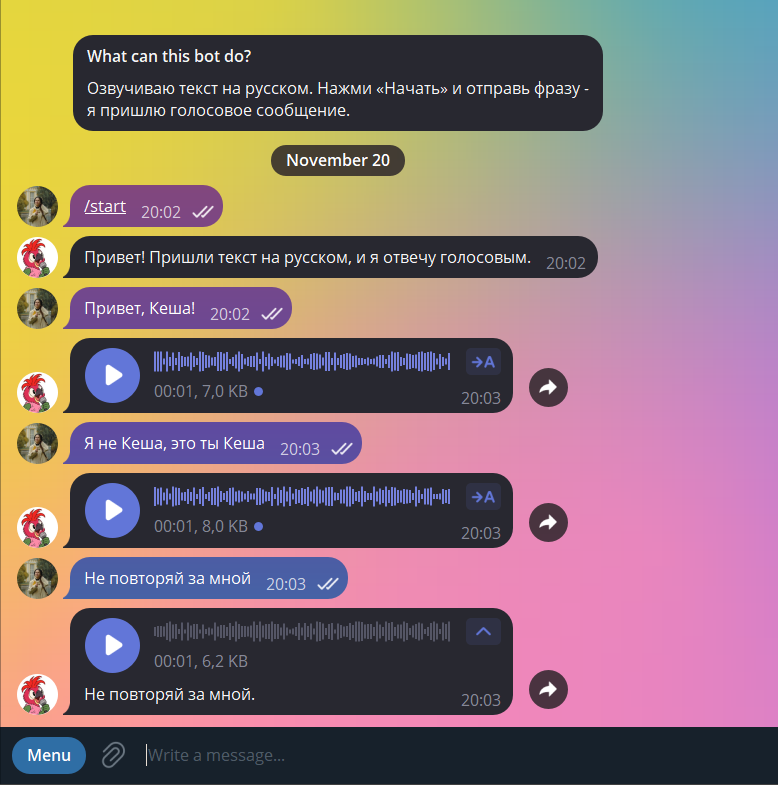

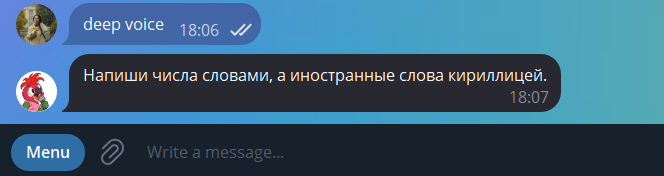

Бот вернул голосовые сообщения для всех тестовых фраз. В eval_08 английские слова при этом были записаны кириллицей, а в eval_09 число - словами. Длинную eval_09 бот синтезировал по частям и отправил одним голосовым сообщением. В eval_10 нормализатор удаляет мусорные символы, за счет чего некоторые слова склеиваются друг с другом, при прослушивании это незаметно.

## Дообучение на корпусе RUSLAN

Дообучен HiFi-GAN из SpeechBrain. Генератор инициализирован весами модели, предобученной на LibriTTS (22 050 Гц), и адаптирован к русской речи диктора RUSLAN. SpeechBrain выбран, чтобы сохранить архитектуру и аудиоконфигурацию исходного вокодера.

| Параметр | Значение |
|---|---|
| Число эпох | 5 |
| Размер батча | 2 |
| Начальная скорость обучения | `2e-5` |
| Критерий отбора чекпоинтов | валидационная ошибка `G_l1_spec_loss` |

Метрики рассчитаны на пяти записях RUSLAN, отложенных отдельно от обучения и валидации. Для прослушивания использованы копи-синтез и синтез на мел-спектрограммах FastSpeech2.

#### Загрузка вокодеров

In [ ]:
original_dir = lab_dir / "pretrained_models" / "hifigan"
finetune_dir = lab_dir / "vocoder_finetune"
run_dir = finetune_dir / "runs" / "full"

weights = {
    "Исходный": original_dir / "generator.ckpt",
    "Эпоха 1": run_dir / "backup_epoch1/CKPT+2026-11-20+22-25-47+00/generator.ckpt",
    "Эпоха 5": run_dir / "save/CKPT+2026-11-22+01-50-52+00/generator.ckpt",
}


def load_vocoder(path):
    with (original_dir / "hyperparams.yaml").open(encoding="utf-8") as file:
        model = load_hyperpyyaml(file)["generator"]
    model.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
    model.eval()
    model.remove_weight_norm()
    return model


vocoders = {name: load_vocoder(path) for name, path in weights.items()}
config_path = lab_dir.parent / "lab4_acoustic" / "saved_runs" / "config.json"
audio_config = json.loads(config_path.read_text(encoding="utf-8"))["audio"]
ap = AudioProcessor.init_from_config(BaseAudioConfig(**audio_config))


@torch.inference_mode()
def vocode_all(mel):
    x = torch.as_tensor(mel, dtype=torch.float32).unsqueeze(0)
    waves = {}
    for name, model in vocoders.items():
        wav = model.inference(x).squeeze().numpy()
        pad = model.inference_padding * ap.hop_length
        waves[name] = wav[pad:len(wav) - pad]
    return waves

#### Метрики копи-синтеза

In [4]:
def spectrum_db(wav):
    magnitude = np.abs(librosa.stft(wav, n_fft=1024, hop_length=256))
    return librosa.amplitude_to_db(magnitude, amin=1e-4, top_db=None)


test_path = finetune_dir / "manifests" / "listen_test.json"
test = json.loads(test_path.read_text(encoding="utf-8"))
examples = {}
rows = []

for phrase_id, item in test.items():
    reference = ap.load_wav(item["wav"])
    waves = vocode_all(ap.melspectrogram(reference))

    length = min(len(reference), *(len(wav) for wav in waves.values()))
    reference = reference[:length]
    waves = {name: wav[:length] for name, wav in waves.items()}
    examples[phrase_id] = (reference, waves)

    ref_mel = ap.melspectrogram(reference)
    ref_db = spectrum_db(reference)

    for name, wav in waves.items():
        mel_error = np.abs(ap.melspectrogram(wav) - ref_mel).mean()
        lsd = np.sqrt(np.mean((spectrum_db(wav) - ref_db) ** 2, axis=0)).mean()
        rows.append({
            "Фраза": phrase_id,
            "Вокодер": name,
            "Log-mel MAE": mel_error,
            "LSD, дБ": lsd,
        })

metrics = pd.DataFrame(rows)
display(metrics.groupby("Вокодер", sort=False)[["Log-mel MAE", "LSD, дБ"]]
        .mean().round(4))

,Log-mel MAE,"LSD, дБ"
Вокодер,,
Исходный,0.2523,10.6709
Эпоха 1,0.1788,8.5964
Эпоха 5,0.1819,8.5392


#### Слуховая оценка

In [8]:
listening = dict(list(examples.items())[:2])
texts = pd.read_csv(
    lab_dir / "data" / "evaluation_text.csv", sep="|", index_col="id"
)["text"]

for phrase_id in ("eval_02", "eval_06"):
    text = texts.loc[phrase_id]
    tokens = pipeline.tokenize(pipeline.normalize(text))
    phones = pipeline.to_phones(pipeline.insert_pauses(tokens))
    listening[f"{phrase_id} — {text}"] = (None, vocode_all(pipeline.mel(phones)))

for label, (reference, waves) in listening.items():
    print(label)

    if reference is not None:
        print("Оригинальная запись")
        display(Audio(reference, rate=SAMPLE_RATE, normalize=False))

    for name, wav in waves.items():
        print(name)
        display(Audio(wav, rate=SAMPLE_RATE, normalize=False))

001850_RUSLAN
Оригинальная запись


Исходный


Эпоха 1


Эпоха 5


006035_RUSLAN
Оригинальная запись


Исходный


... (4 outputs left out)

Эпоха 5


eval_06 — Бык тупогуб, тупогубенький бычок, у быка бела губа была тупа.
Исходный


Эпоха 1


Эпоха 5


#### Результаты и вывод

| Вокодер | Log-mel MAE | LSD, дБ |
|---|---:|---:|
| Исходный | 0.2523 | 10.6709 |
| Эпоха 1 | 0.1788 | 8.5964 |
| Эпоха 5 | 0.1819 | 8.5392 |

На пяти отложенных записях RUSLAN дообучение снизило обе спектральные ошибки. 
- Минимальный Log-mel MAE получен после первой эпохи (0,1788), 
- Минимальный LSD - после пятой (8,5392 дБ).

Дообучение улучшило спектральное сходство в копи-синтезе. При прослушивании записей 001850_RUSLAN и 006035_RUSLAN заметной разницы между вокодерами не было. На фразах eval_02 и eval_06 с мел-спектрограммами от FastSpeech2 после дообучения появились слабый присвист и дребезжание, а исходный вокодер звучал немного чище, поэтому в тракте оставлен исходный HiFi-GAN.